In [14]:
# antes de nada, importamos las librerías necesarias
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from scipy.integrate import solve_ivp
import os
from matplotlib.animation import FFMpegWriter

# nos aseguramos de que el directorio donde se guardarán las figuras exista
os.makedirs("figuras", exist_ok=True)

### Ejercicio 1: simulación de un oscilador armónico

In [15]:
# establecemos los parámetros.

# Constantes físicas
m = 2.66e-26  # kg
mu = m / 2
f = 4.7e13    # Hz
omega = 2 * np.pi * f
k = mu * omega**2

# Condiciones iniciales
x0 = 1e-11    # desplazamiento pequeño en metros (~0.01 Å)
v0 = 0.0

# Tiempo: queremos observar unos cuantos periodos
T = 1 / f
t_span = (0, 3 * T)
nt = 1000
t_eval = np.linspace(t_span[0], t_span[1], nt)

# Ecuación diferencial
def harmonic_oscillator(t, y):
    x, v = y
    return [v, -omega**2 * x]

# calculamos la solución numérica
sol = solve_ivp(harmonic_oscillator, t_span, [x0, v0], t_eval=t_eval, method ='DOP853')

# y calculamos la solución analítica
x_analytic = x0 * np.cos(omega * t_eval) + (v0 / omega) * np.sin(omega * t_eval)

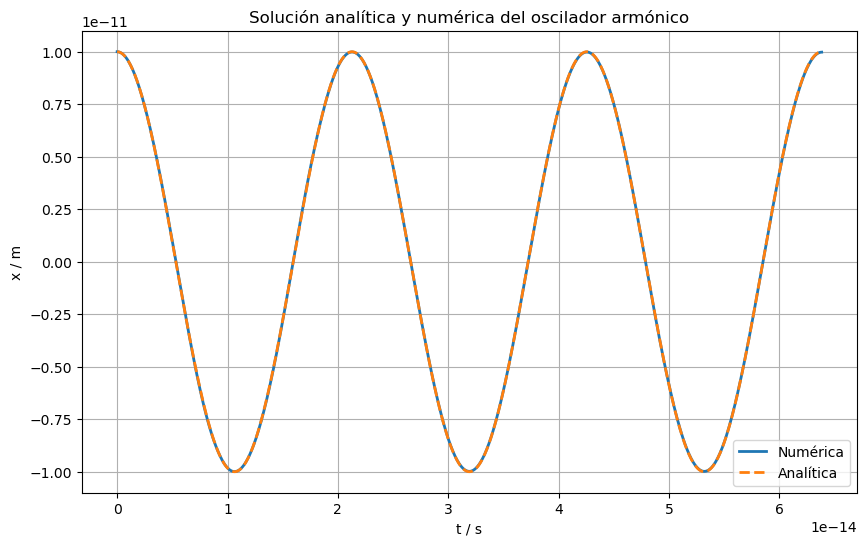

In [3]:
# finalmente, graficamos ambos resultados
plt.figure(figsize=(10, 6))
plt.plot(t_eval, sol.y[0], label='Numérica', lw=2)
plt.plot(t_eval, x_analytic, '--', label='Analítica', lw=2)
plt.xlabel('t / s')
plt.ylabel('x / m')
plt.title('Solución analítica y numérica del oscilador armónico')
plt.legend(loc='lower right')
plt.grid(True)
plt.savefig('figuras/e1_soluciones.png', bbox_inches='tight') # guardamos el gráfico
plt.show()

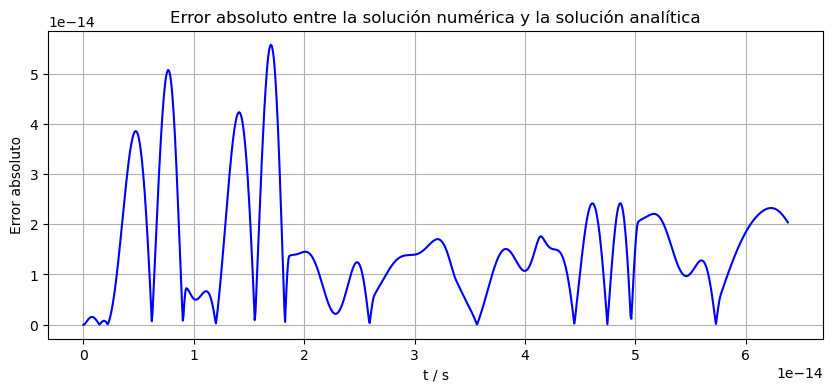

In [16]:
# además, vamos a analilzar el error de la solución numérica
error = np.abs(sol.y[0] - x_analytic)
plt.figure(figsize=(10, 4))
plt.plot(t_eval, error, label='Absolute Error', color='blue')
plt.xlabel('t / s')
plt.ylabel('Error absoluto')
plt.title('Error absoluto entre la solución numérica y la solución analítica')
plt.grid(True)
plt.savefig('figuras/e1_error_absoluto.png', bbox_inches='tight') # guardamos el gráfico
plt.show()

### Ejericio 2: energía del oscilador armónico

In [29]:
# Parámetros físicos modificados
omega = 2.0  # Frecuencia angular mayor
x0 = 2.0     # Mayor amplitud inicial
v0 = 5.0     # Velocidad inicial no nula
m = 1.0
k = m * omega**2
gamma = 0.5 # Gamma constante

# array de tiempos
t = np.linspace(0, 20, 1000)

# soluciones analíticas
x = x0 * np.cos(omega * t) + (v0 / omega) * np.sin(omega * t)
v = -x0 * omega * np.sin(omega * t) + v0 * np.cos(omega * t)
a = -omega**2 * x - gamma * v**2

# energías
K = 0.5 * m * v**2
U = 0.5 * k * x**2

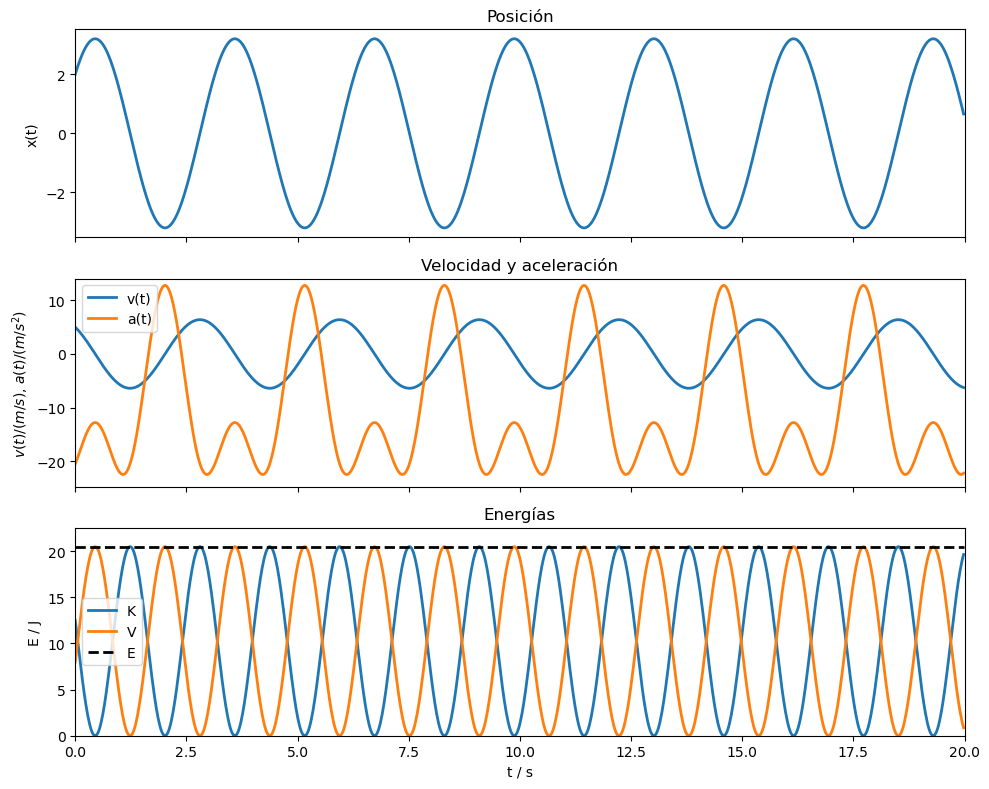

In [30]:
# creamos las figuras y los ejes
fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
lines = []

# panel 1: posición
axs[0].set_title('Posición')
axs[0].set_ylabel('x(t)')
axs[0].set_xlim(t[0], t[-1])
axs[0].set_ylim(1.1 * np.min(x), 1.1 * np.max(x))
line_x, = axs[0].plot([], [], lw=2)
lines.append(line_x)

# panel 2: velocidad y aceleración
axs[1].set_title('Velocidad y aceleración')
axs[1].set_ylabel('$v(t) / (m/s)$, $a(t) / (m/s^2)$')
axs[1].set_xlim(t[0], t[-1])
axs[1].set_ylim(1.1 * np.min(np.concatenate([v, a])), 1.1 * np.max(np.concatenate([v, a])))
line_v, = axs[1].plot([], [], label='v(t)', lw=2)
line_a, = axs[1].plot([], [], label='a(t)', lw=2)
axs[1].legend()
lines.extend([line_v, line_a])

# panel 3: energías
axs[2].set_title('Energías')
axs[2].set_xlabel('t / s')
axs[2].set_ylabel('E / J')
axs[2].set_xlim(t[0], t[-1])
axs[2].set_ylim(0, 1.1 * np.max(K + U))
line_k, = axs[2].plot([], [], label='K', lw=2)
line_u, = axs[2].plot([], [], label='V', lw=2)
line_e, = axs[2].plot([], [], label='E', lw=2, linestyle='--', color='black')
axs[2].legend()
lines.extend([line_k, line_u, line_e])

# inicializamos las líneas
def init():
    for line in lines:
        line.set_data([], [])
    return lines

# Función de actualización para la animación
def update(frame):
    t_now = t[:frame]
    lines[0].set_data(t_now, x[:frame])
    lines[1].set_data(t_now, v[:frame])
    lines[2].set_data(t_now, a[:frame])
    lines[3].set_data(t_now, K[:frame])
    lines[4].set_data(t_now, U[:frame])
    lines[5].set_data(t_now, (K + U)[:frame])
    return lines

# Animate
ani = FuncAnimation(fig, update, frames=len(t), init_func=init, blit=True)

plt.tight_layout()

# Save the animation
writer = FFMpegWriter(fps=30, bitrate=1800)
ani.save("figuras/e2_animacion.mp4", writer=writer)

# guardamos el último fotograma, a modo de figura
fig.savefig("figuras/e2_figura.png", dpi=300)

# Ejercicio 3: Pulso en una cuerda

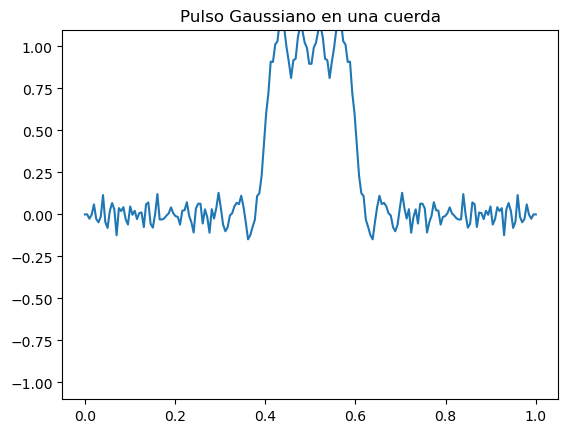

In [38]:
# Parámetros
L = 1.0          # Longitud de la cuerta
N = 200          # Numero de puntos espaciales
c = 1.0          # Velocidad de la onda 
dx = L / (N - 1)
x = np.linspace(0, L, N)
dt = 0.5 * dx / c 
T = 2.0          # Tiempo final
steps = int(T / dt)

# Pulso (gaussiano) inicial
def initial_pulse(x):
    return np.where((x > 0.4) & (x < 0.6), 1.0, 0.0)

# Arrays donde guardamos los resultados
u = initial_pulse(x)
u_old = u.copy()
u_new = np.zeros(N)

# Condiciles de contorno fijas para la cuerda
u[0] = u[-1] = 0
u_old[0] = u_old[-1] = 0

# Cantidad constante a lo largo del codigo
C2 = (c * dt / dx) ** 2

# Preparamos el gráfico
fig, ax = plt.subplots()
line, = ax.plot(x, u)
ax.set_ylim(-1.1, 1.1)
ax.set_title("Pulso Gaussiano en una cuerda")

# Animation update
def update(frame):
    global u, u_old, u_new
    for i in range(1, N - 1):
        u_new[i] = 2*u[i] - u_old[i] + C2 * (u[i+1] - 2*u[i] + u[i-1])
    u_new[0] = u_new[-1] = 0  # fixed ends
    u_old, u = u, u_new.copy()
    line.set_ydata(u)
    return line,

ani = FuncAnimation(fig, update, frames=steps, interval=20, blit=True)

# Guardamos la animación
ani.save("figuras/e3_animacion.mp4", fps=30, bitrate=1800)

# Y guardamos el último fotograma, a modo de figura
fig.savefig("figuras/e2_figura.png", dpi=300)

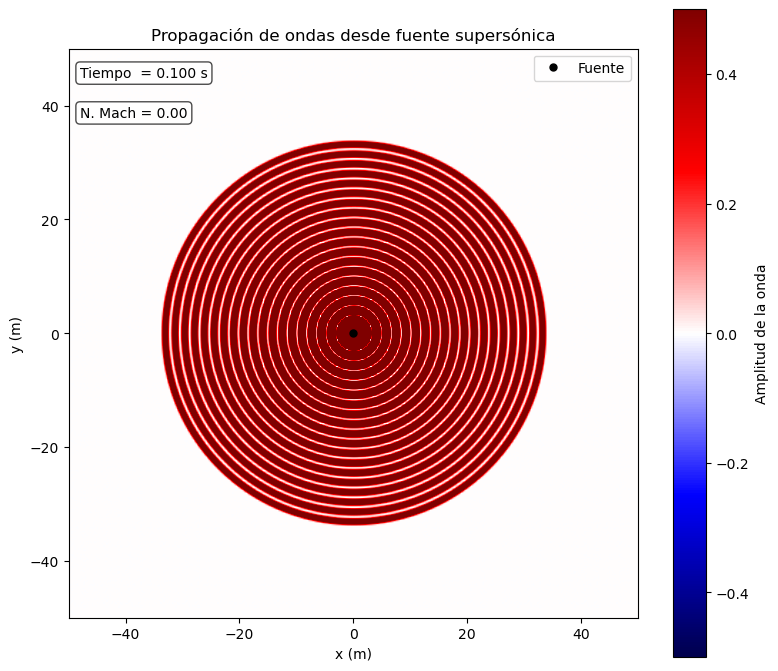

In [46]:
# Parámetros de la simulación
c = 343.0                        # Velocidad del sonido (m/s)
v_s = 0 * c                    # Velocidad de la fuente (supersónica)
t_max = 0.1                      # Tiempo total a simular (s)
dt = 0.0005                      # Paso de tiempo de emisión (s) - más pequeño para mejor resultado, a costa de mayor tiempo de espera
num_frames = 200                 # Número de fotogramas en la animación
grid_size = 400                  # Resolución de puntos donde hacemos la simulación 2D
x = np.linspace(-50, 50, grid_size) # Rango de coordenadas en el eje x (m)
y = np.linspace(-50, 50, grid_size) # Rango de coordenadas en el eje y (m)
X, Y = np.meshgrid(x, y)         # Creamos la rejilla de puntos

# Configuramos la figura
fig, ax = plt.subplots(figsize=(8, 7))
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("Propagación de ondas desde fuente supersónica")
ax.set_aspect('equal', adjustable='box')

# Campo inicial nulo
initial_field = np.zeros_like(X)

# Estimamos vmin/vmax, se puede cambiar para adaptarlo a tus resultados
v_min_est = -0.5
v_max_est = 0.5

# Graficamos el campo de ondas con una barra de color
field_im = ax.imshow(initial_field, extent=[x.min(), x.max(), y.min(), y.max()],
                     origin='lower', cmap='seismic', vmin=v_min_est, vmax=v_max_est,
                     interpolation='bilinear')
fig.colorbar(field_im, label="Amplitud de la onda")

# Objeto de trazado para la posición de la fuente (inicialmente vacío)
# Trazamos un solo punto, por lo que set_data esperará secuencias (listas/matrices)
source_dot, = ax.plot([], [], 'ko', markersize=5, label='Fuente') # Círculo negro para la fuente

# Anotaciones de texto para el tiempo y el número de Mach
time_text = ax.text(0.02, 0.95, '', transform=ax.transAxes, fontsize=10, color='black',
                    bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.7))
mach_text = ax.text(0.02, 0.88, '', transform=ax.transAxes, fontsize=10, color='black',
                    bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.7))

ax.legend(loc='upper right')

# Posición inicial
x0 = 0 * x.max() # Empieza cerca del borde izquierdo
emitted_waves = []   # Lista para guardar las ondas emitidas (t_emit, x_emit)

# Modelo de onda
def monopole_wave(x_s, t_emit, t_now):
    """
    Calculates the wave field from a single pulse emitted at (x_s, 0) at time t_emit,
    observed at time t_now.
    Args:
        x_s (float): Source x-position at emission time.
        t_emit (float): Time the pulse was emitted.
        t_now (float): Current observation time.
    Returns:
        np.ndarray: The wave field contribution from this pulse.
    """
    # Distancia desde el punto de emisión de la fuente hasta los puntos de la rejilla
    r = np.sqrt((X - x_s)**2 + Y**2)
    # Tiempo transcurrido desde la emisión
    t_delay = t_now - t_emit
    # Tiempo de viaje de la onda hasta los puntos de la rejilla
    t_travel = r / c

    # Calcular el campo de onda solo donde t_delay >= t_travel
    # Usar un pulso de onda senoidal con decaimiento simple
    frequency = 200  # Hz - frecuencia de la fuente de la onda
    amplitude_factor = 10  # Factor de amplitud aumentado para visibilidad

    # Usar errstate para suprimir posibles advertencias por división por cero cerca de la fuente
    with np.errstate(divide='ignore', invalid='ignore'):
        # Calcular el argumento de la onda senoidal
        wave_arg = 2 * np.pi * frequency * (t_delay - t_travel)
        # Calcular el campo: amplitud * sin(wave_arg) / r
        # Asegurar que el campo sea cero si r es muy pequeño o si la onda aún no ha llegado
        field = np.where(
            (t_delay >= t_travel) & (r > 1e-6),
            amplitude_factor * np.sin(wave_arg) / r,
            0.0
        )
        # Manejar posibles NaNs resultantes de la división por cero si r=0
        field = np.nan_to_num(field)

    return field

# --- Función de actualización de la animación ---
def update(frame):
    """
    Actualiza la animación para cada fotograma.
    Args:
        frame (int): El número del fotograma actual.
    Returns:
        list: Una lista de artistas que han sido modificados.
    """
    global emitted_waves  # Permitir modificación de la lista global

    # Calcular el tiempo físico actual para este fotograma
    t_now = frame / num_frames * t_max

    # Calcular la posición actual de la fuente
    x_s_now = x0 + v_s * t_now

    # Emitir nuevos pulsos de onda desde el último fotograma
    # Determinar el tiempo del último pulso emitido (o tiempo de inicio si no hay ninguno)
    last_t_emit = emitted_waves[-1][0] if emitted_waves else 0.0
    # Emitir pulsos a intervalos de dt hasta el tiempo actual t_now
    t_emit_candidate = last_t_emit + dt
    while t_emit_candidate <= t_now:
        x_emit = x0 + v_s * t_emit_candidate
        # Agregar el tiempo y posición de emisión a la lista
        emitted_waves.append((t_emit_candidate, x_emit))
        t_emit_candidate += dt

    # Calcular el campo de onda total sumando las contribuciones de todos los pulsos emitidos
    total_field = np.zeros_like(X)
    if emitted_waves:  # Calcular solo si se han emitido ondas
        for t_e, x_e in emitted_waves:
            total_field += monopole_wave(x_e, t_e, t_now)

    # Actualizar los datos de la gráfica
    field_im.set_data(total_field)

    # Actualizar el marcador de posición de la fuente
    # *** ARREGLO: Pasar coordenadas como listas/secuecias ***
    source_dot.set_data([x_s_now], [0])

    # Actualizar el texto de tiempo y número de Mach
    time_text.set_text(f"Tiempo  = {t_now:.3f} s")
    mach_text.set_text(f"N. Mach = {v_s / c:.2f}")

    # Opcional: Ajustar límites de color dinámicamente según mínimo/máximo del campo actual
    # current_min = np.min(total_field)
    # current_max = np.max(total_field)
    # if not np.isclose(current_min, current_max):  # Evitar ajustar límites si el campo es homogéneo
    #    field_im.set_clim(vmin=np.percentile(total_field, 1), vmax=np.percentile(total_field, 99))  # Usar percentiles para robustez

    # Devolver la lista de artistas modificados para blitting
    return [field_im, source_dot, time_text, mach_text]

# --- Crear animación ---
# Usar blit=True para un renderizado potencialmente más rápido, pero que a veces puede causar problemas.
# Si la animación falla, probar con blit=False.
ani = FuncAnimation(fig, update, frames=num_frames,
                              interval=50,  # Retardo entre fotogramas en milisegundos (p.ej., 50ms -> 20 fps)
                              blit=True,
                              repeat=False)  # No repetir la animación

plt.tight_layout()

ani.save("figuras/e4_animacion.mp4", fps=30, bitrate=1800)

# Guardamos el último fotograma como figura
fig.savefig("figuras/e4_figura.png", dpi=300)
